<a href="https://colab.research.google.com/github/ShubhGuPTA-cmd/ML-experiments/blob/main/HMM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

!pip install hmmlearn scikit-learn seaborn matplotlib pandas numpy

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from hmmlearn.hmm import CategoricalHMM

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

from scipy.optimize import linear_sum_assignment

np.random.seed(42)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
states = [
    "Healthy",
    "Mild Infection",
    "Severe Infection"
]

symptoms = [
    "Normal",
    "Mild Fever",
    "High Fever",
    "Breathing Difficulty"
]

n_states = len(states)
n_observations = len(symptoms)

print("Hidden States:", states)
print("Observable Symptoms:", symptoms)

Hidden States: ['Healthy', 'Mild Infection', 'Severe Infection']
Observable Symptoms: ['Normal', 'Mild Fever', 'High Fever', 'Breathing Difficulty']


In [ ]:
# Initial state probabilities
initial_prob = np.array([0.60, 0.30, 0.10])

# Transition probability matrix
transition_matrix = np.array([
    [0.80, 0.18, 0.02],
    [0.10, 0.70, 0.20],
    [0.02, 0.18, 0.80]
])

# Emission probability matrix
emission_matrix = np.array([
    [0.85, 0.12, 0.02, 0.01],
    [0.15, 0.60, 0.20, 0.05],
    [0.02, 0.13, 0.35, 0.50]
])

print("Initial Probability:")
print(initial_prob)

print("\nTransition Matrix:")
print(transition_matrix)

print("\nEmission Matrix:")
print(emission_matrix)

Initial Probability:
[0.6 0.3 0.1]

Transition Matrix:
[[0.8  0.18 0.02]
 [0.1  0.7  0.2 ]
 [0.02 0.18 0.8 ]]

Emission Matrix:
[[0.85 0.12 0.02 0.01]
 [0.15 0.6  0.2  0.05]
 [0.02 0.13 0.35 0.5 ]]


In [ ]:
n_patients = 500
sequence_length = 10

all_states = []
all_observations = []

for patient in range(n_patients):

    patient_states = []
    patient_observations = []

    # Select initial hidden state
    current_state = np.random.choice(
        n_states,
        p=initial_prob
    )

    for day in range(sequence_length):

        # Generate observable symptom
        symptom = np.random.choice(
            n_observations,
            p=emission_matrix[current_state]
        )

        patient_states.append(current_state)
        patient_observations.append(symptom)

        # Generate next hidden state
        current_state = np.random.choice(
            n_states,
            p=transition_matrix[current_state]
        )

    all_states.append(patient_states)
    all_observations.append(patient_observations)

all_states = np.array(all_states)
all_observations = np.array(all_observations)

print("Dataset generated successfully!")
print("Number of patients:", len(all_observations))
print("Observations per patient:", sequence_length)
print("Total observations:", all_observations.size)

Dataset generated successfully!
Number of patients: 500
Observations per patient: 10
Total observations: 5000


In [ ]:
data = []

for i in range(n_patients):

    for day in range(sequence_length):

        data.append({
            "Patient_ID": i + 1,
            "Day": day + 1,
            "Actual_State": states[all_states[i][day]],
            "Observed_Symptom": symptoms[all_observations[i][day]]
        })

df = pd.DataFrame(data)

print(df.head(20))

    Patient_ID  Day      Actual_State      Observed_Symptom
0            1    1           Healthy            Mild Fever
1            1    2           Healthy                Normal
2            1    3           Healthy                Normal
3            1    4           Healthy            Mild Fever
4            1    5           Healthy                Normal
5            1    6           Healthy            Mild Fever
6            1    7    Mild Infection            Mild Fever
7            1    8    Mild Infection            Mild Fever
8            1    9    Mild Infection            Mild Fever
9            1   10    Mild Infection            Mild Fever
10           2    1           Healthy                Normal
11           2    2           Healthy                Normal
12           2    3           Healthy                Normal
13           2    4           Healthy                Normal
14           2    5           Healthy                Normal
15           2    6           Healthy   

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    all_observations,
    all_states,
    test_size=0.20,
    random_state=42
)

print("Training patients:", len(X_train))
print("Testing patients:", len(X_test))

Training patients: 400
Testing patients: 100


In [ ]:
# Combine training observations
X_train_flat = X_train.reshape(-1, 1)

# Each patient is an independent sequence
lengths = [sequence_length] * len(X_train)

# Create HMM model
model = CategoricalHMM(
    n_components=3,
    n_features=4,
    n_iter=100,
    tol=0.001,
    random_state=42,
    init_params="",
    params="ste"
)

# Initialize probabilities
model.startprob_ = np.array([0.55, 0.30, 0.15])

model.transmat_ = np.array([
    [0.75, 0.20, 0.05],
    [0.15, 0.65, 0.20],
    [0.05, 0.20, 0.75]
])

model.emissionprob_ = np.array([
    [0.80, 0.15, 0.03, 0.02],
    [0.15, 0.55, 0.25, 0.05],
    [0.03, 0.12, 0.35, 0.50]
])

# Train using observations only
model.fit(X_train_flat, lengths)

print("HMM training completed!")

HMM training completed!


In [ ]:
print("Estimated Initial State Probabilities:")
print(model.startprob_)

print("\nEstimated Transition Matrix:")
print(model.transmat_)

print("\nEstimated Emission Matrix:")
print(model.emissionprob_)

Estimated Initial State Probabilities:
[0.58400078 0.29672522 0.119274  ]

Estimated Transition Matrix:
[[0.78807736 0.17666266 0.03525999]
 [0.12161631 0.74565145 0.13273224]
 [0.0062392  0.15467855 0.83908225]]

Estimated Emission Matrix:
[[0.87079118 0.10562589 0.01985476 0.00372818]
 [0.15114938 0.59457279 0.20497855 0.04929929]
 [0.02947724 0.18194751 0.330187   0.45838825]]


In [ ]:
# Select one test patient
sample_sequence = X_test[0].reshape(-1, 1)

# Calculate log probability
log_probability = model.score(sample_sequence)

# Convert to probability
probability = np.exp(log_probability)

print("Observed Symptom Sequence:")

print([
    symptoms[i] for i in X_test[0]
])

print("\nLog Probability:", log_probability)

print("Sequence Probability:", probability)

Observed Symptom Sequence:
['Normal', 'Normal', 'Normal', 'Normal', 'Normal', 'Mild Fever', 'Mild Fever', 'High Fever', 'Breathing Difficulty', 'Normal']

Log Probability: -10.56938216700944
Sequence Probability: 2.5690682844985755e-05


In [ ]:
predicted_states = []

for sequence in X_test:

    sequence = sequence.reshape(-1, 1)

    # Predict hidden states
    log_prob, hidden_sequence = model.decode(
        sequence,
        algorithm="viterbi"
    )

    predicted_states.append(hidden_sequence)

predicted_states = np.array(predicted_states)

print("Viterbi prediction completed!")

Viterbi prediction completed!


In [ ]:
patient_number = 0

print("Observed Symptoms:")

print([
    symptoms[i] for i in X_test[patient_number]
])

print("\nActual Disease States (evaluation only):")

print([
    states[i] for i in y_test[patient_number]
])

print("\nPredicted Disease States:")

print([
    states[i] for i in predicted_states[patient_number]
])

Observed Symptoms:
['Normal', 'Normal', 'Normal', 'Normal', 'Normal', 'Mild Fever', 'Mild Fever', 'High Fever', 'Breathing Difficulty', 'Normal']

Actual Disease States (evaluation only):
['Healthy', 'Healthy', 'Healthy', 'Healthy', 'Healthy', 'Mild Infection', 'Severe Infection', 'Severe Infection', 'Healthy', 'Healthy']

Predicted Disease States:
['Healthy', 'Healthy', 'Healthy', 'Healthy', 'Healthy', 'Mild Infection', 'Mild Infection', 'Mild Infection', 'Mild Infection', 'Mild Infection']


In [ ]:
y_true = y_test.flatten()
y_pred = predicted_states.flatten()

# Find best one-to-one mapping for evaluation
cm_raw = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2]
)

row_ind, col_ind = linear_sum_assignment(-cm_raw)

mapping = {
    predicted: actual
    for actual, predicted in zip(row_ind, col_ind)
}

y_pred_aligned = np.array([
    mapping[p] for p in y_pred
])

# Calculate performance metrics
accuracy = accuracy_score(
    y_true, y_pred_aligned
)

precision = precision_score(
    y_true, y_pred_aligned,
    average="macro",
    zero_division=0
)

recall = recall_score(
    y_true, y_pred_aligned,
    average="macro",
    zero_division=0
)

f1 = f1_score(
    y_true, y_pred_aligned,
    average="macro",
    zero_division=0
)

print("MODEL PERFORMANCE")

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

MODEL PERFORMANCE
Accuracy: 81.7 %
Precision: 81.16 %
Recall: 81.74 %
F1 Score: 81.41 %


In [ ]:
print(classification_report(
    y_true,
    y_pred_aligned,
    labels=[0, 1, 2],
    target_names=states,
    zero_division=0
))

                  precision    recall  f1-score   support

         Healthy       0.89      0.86      0.88       405
  Mild Infection       0.76      0.75      0.75       354
Severe Infection       0.79      0.84      0.82       241

        accuracy                           0.82      1000
       macro avg       0.81      0.82      0.81      1000
    weighted avg       0.82      0.82      0.82      1000



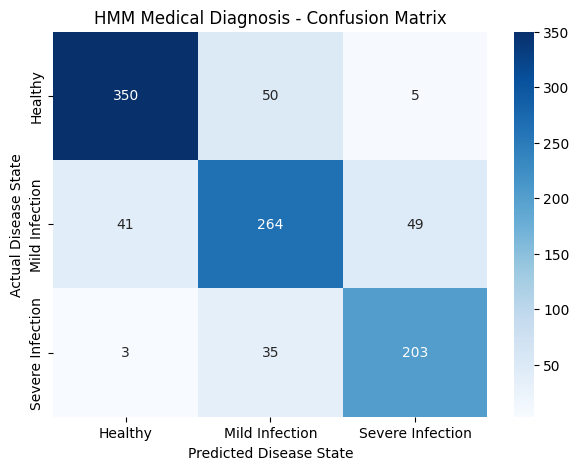

In [ ]:
cm = confusion_matrix(
    y_true,
    y_pred_aligned,
    labels=[0, 1, 2]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=states,
    yticklabels=states
)

plt.xlabel("Predicted Disease State")
plt.ylabel("Actual Disease State")
plt.title("HMM Medical Diagnosis - Confusion Matrix")

plt.show()

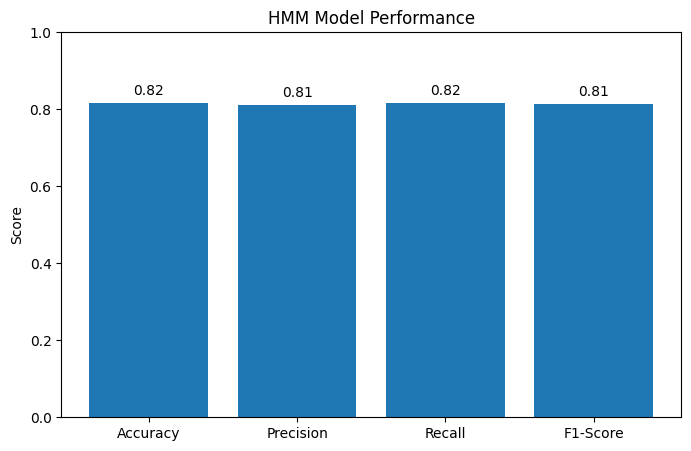

In [ ]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-Score": f1
}

plt.figure(figsize=(8, 5))

plt.bar(metrics.keys(), metrics.values())

plt.ylim(0, 1)

plt.ylabel("Score")
plt.title("HMM Model Performance")

for i, value in enumerate(metrics.values()):
    plt.text(i, value + 0.02, f"{value:.2f}", ha="center")

plt.show()

Patients: 100 | Accuracy: 76.5 %
Patients: 250 | Accuracy: 81.0 %
Patients: 500 | Accuracy: 83.0 %


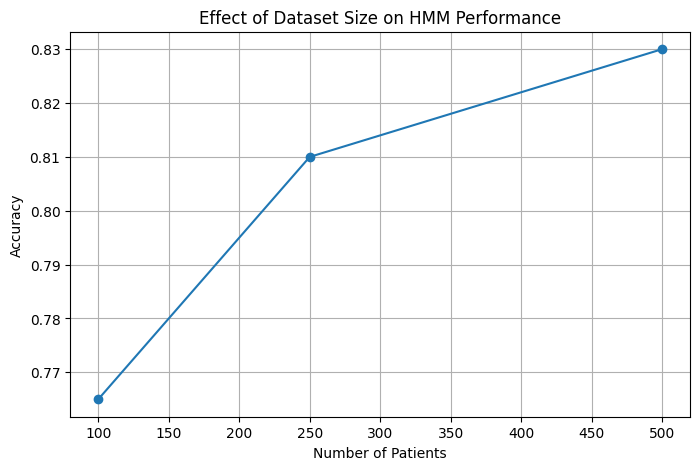

In [ ]:
def generate_data(n_patients, seq_length, seed=42):

    rng = np.random.default_rng(seed)

    hidden = []
    observed = []

    for _ in range(n_patients):

        current = rng.choice(3, p=initial_prob)

        patient_hidden = []
        patient_observed = []

        for _ in range(seq_length):

            symptom = rng.choice(
                4, p=emission_matrix[current]
            )

            patient_hidden.append(current)
            patient_observed.append(symptom)

            current = rng.choice(
                3, p=transition_matrix[current]
            )

        hidden.append(patient_hidden)
        observed.append(patient_observed)

    return np.array(hidden), np.array(observed)


def evaluate_hmm(n_patients, seq_length):

    hidden, observed = generate_data(
        n_patients, seq_length
    )

    Xtr, Xte, ytr, yte = train_test_split(
        observed, hidden,
        test_size=0.20,
        random_state=42
    )

    hmm = CategoricalHMM(
        n_components=3,
        n_features=4,
        n_iter=100,
        tol=0.001,
        random_state=42,
        init_params="",
        params="ste"
    )

    hmm.startprob_ = np.array([0.55, 0.30, 0.15])

    hmm.transmat_ = np.array([
        [0.75, 0.20, 0.05],
        [0.15, 0.65, 0.20],
        [0.05, 0.20, 0.75]
    ])

    hmm.emissionprob_ = np.array([
        [0.80, 0.15, 0.03, 0.02],
        [0.15, 0.55, 0.25, 0.05],
        [0.03, 0.12, 0.35, 0.50]
    ])

    hmm.fit(
        Xtr.reshape(-1, 1),
        [seq_length] * len(Xtr)
    )

    predictions = []

    for seq in Xte:

        _, pred = hmm.decode(
            seq.reshape(-1, 1),
            algorithm="viterbi"
        )

        predictions.extend(pred)

    true = yte.flatten()
    pred = np.array(predictions)

    # Align state numbers for evaluation only
    matrix = confusion_matrix(
        true, pred, labels=[0, 1, 2]
    )

    rows, cols = linear_sum_assignment(-matrix)

    mapping = dict(zip(cols, rows))

    pred = np.array([mapping[p] for p in pred])

    return accuracy_score(true, pred)


dataset_sizes = [100, 250, 500]

dataset_results = []

for size in dataset_sizes:

    score = evaluate_hmm(size, 10)

    dataset_results.append(score)

    print(
        "Patients:", size,
        "| Accuracy:", round(score * 100, 2), "%"
    )


plt.figure(figsize=(8, 5))

plt.plot(
    dataset_sizes,
    dataset_results,
    marker="o"
)

plt.xlabel("Number of Patients")
plt.ylabel("Accuracy")
plt.title("Effect of Dataset Size on HMM Performance")

plt.grid(True)
plt.show()

In [ ]:
results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-Score"
    ],
    "Score (%)": [
        accuracy * 100,
        precision * 100,
        recall * 100,
        f1 * 100
    ]
})

print(results)

      Metric  Score (%)
0   Accuracy  81.700000
1  Precision  81.155171
2     Recall  81.742796
3   F1-Score  81.414101
